In [1]:
import numpy as np
import nibabel as nib
from pathlib import Path
from collections import Counter


Cargamos los datos

In [2]:
import numpy as np
import nibabel as nib

def squeeze_volume(vol):
    """
    Elimina canal extra si el volumen es (X,Y,Z,1)
    """
    if vol.ndim == 4 and vol.shape[-1] == 1:
        return vol[..., 0]
    return vol


def load_atlases_for_fixed(fixed_dir):
    """
    Carga intensidades y labels de todos los atlas
    registrados en el espacio de un fixed.

    Devuelve:
      intensities: (N, X, Y, Z)
      labels:      (N, X, Y, Z)
      affine, header
    """

    intensities = []
    labels = []
    affine = None
    header = None

    for moving_dir in fixed_dir.glob("moving_*"):

        img_path = moving_dir / "result_intensity.nii.gz"
        lab_path = moving_dir / "result_labels.nii.gz"

        if not img_path.exists() or not lab_path.exists():
            continue

        # ---------- Intensidades ----------
        img = nib.load(img_path)
        img_data = img.get_fdata().astype(np.float32)

        if img_data.ndim == 4 and img_data.shape[-1] == 1:
            img_data = img_data[..., 0]

        # ---------- Labels ----------
        lab = nib.load(lab_path)
        lab_data = lab.get_fdata().astype(np.int16)

        if lab_data.ndim == 4 and lab_data.shape[-1] == 1:
            lab_data = lab_data[..., 0]

        intensities.append(img_data)
        labels.append(lab_data)

        if affine is None:
            affine = lab.affine
            header = lab.header

    intensities = np.asarray(intensities)
    labels = np.asarray(labels)

    return intensities, labels, affine, header

def load_ground_truth(gt_path):
    gt = nib.load(gt_path).get_fdata().astype(np.int16)

    # FIX: eliminar canal extra si existe
    if gt.ndim == 4 and gt.shape[-1] == 1:
        gt = gt[..., 0]

    return gt


Funcion para normalizar

In [3]:
def zscore_volume(vol, mask=None, eps=1e-8):
    """
    Z-score normalisation of a 3D volume.
    If mask is provided, statistics are computed only inside the mask.
    """
    if mask is None:
        mask = vol > 0

    mean = vol[mask].mean()
    std = vol[mask].std()

    return (vol - mean) / (std + eps)

def zscore_atlases(atlas_imgs):
    norm_imgs = np.zeros_like(atlas_imgs)
    for i in range(atlas_imgs.shape[0]):
        norm_imgs[i] = zscore_volume(atlas_imgs[i])
    return norm_imgs


FUNCIONES DE EVALUACIÓN DE LA SEGMENTACIÓN

In [4]:
def dice_per_label(seg, gt, labels=None):
    if labels is None:
        labels = np.unique(gt)
        labels = labels[labels != 0]  # ignorar fondo

    dice_scores = {}

    for lab in labels:
        seg_bin = (seg == lab)
        gt_bin = (gt == lab)

        inter = np.logical_and(seg_bin, gt_bin).sum()
        denom = seg_bin.sum() + gt_bin.sum()

        dice_scores[int(lab)] = (
            2 * inter / denom if denom > 0 else np.nan
        )

    return dice_scores, np.nanmean(list(dice_scores.values()))



def dice_per_atlas(labels_stack, gt):
    """
    labels_stack: (N, X, Y, Z)
    gt: (X, Y, Z)
    """
    dice_scores = []

    for i in range(labels_stack.shape[0]):
        _, dice_mean = dice_per_label(
            labels_stack[i], gt
        )
        dice_scores.append(dice_mean)

    return np.array(dice_scores)


In [5]:
import SimpleITK as sitk

def hausdorff_distance(seg, gt, label):
    seg_bin = (seg == label).astype(np.uint8)
    gt_bin = (gt == label).astype(np.uint8)

    seg_itk = sitk.GetImageFromArray(seg_bin)
    gt_itk = sitk.GetImageFromArray(gt_bin)

    hd_filter = sitk.HausdorffDistanceImageFilter()
    hd_filter.Execute(seg_itk, gt_itk)

    return hd_filter.GetHausdorffDistance()


In [6]:
def average_volumetric_difference(seg, gt, label):
    vol_seg = np.sum(seg == label)
    vol_gt = np.sum(gt == label)

    if vol_gt == 0:
        return np.nan

    return abs(vol_seg - vol_gt) / vol_gt


In [8]:
def dice_score(seg, gt, label):
    seg_bin = (seg == label)
    gt_bin = (gt == label)

    inter = np.logical_and(seg_bin, gt_bin).sum()
    denom = seg_bin.sum() + gt_bin.sum()

    return 2 * inter / denom if denom > 0 else np.nan

import numpy as np
import SimpleITK as sitk

def hausdorff_95(seg, gt, label):
    seg_bin = (seg == label).astype(np.uint8)
    gt_bin = (gt == label).astype(np.uint8)

    if np.sum(seg_bin) == 0 or np.sum(gt_bin) == 0:
        return np.nan

    seg_itk = sitk.GetImageFromArray(seg_bin)
    gt_itk  = sitk.GetImageFromArray(gt_bin)

    # Distance maps
    seg_dist = sitk.Abs(
        sitk.SignedMaurerDistanceMap(
            seg_itk, squaredDistance=False, useImageSpacing=False
        )
    )
    gt_dist = sitk.Abs(
        sitk.SignedMaurerDistanceMap(
            gt_itk, squaredDistance=False, useImageSpacing=False
        )
    )

    # Surfaces
    seg_surf = sitk.LabelContour(seg_itk)
    gt_surf  = sitk.LabelContour(gt_itk)

    seg_surf_arr = sitk.GetArrayFromImage(seg_surf) > 0
    gt_surf_arr  = sitk.GetArrayFromImage(gt_surf) > 0

    # Distances from surface to opposite object
    dists_seg_to_gt = sitk.GetArrayFromImage(gt_dist)[seg_surf_arr]
    dists_gt_to_seg = sitk.GetArrayFromImage(seg_dist)[gt_surf_arr]

    all_dists = np.concatenate([dists_seg_to_gt, dists_gt_to_seg])

    if all_dists.size == 0:
        return np.nan

    return np.percentile(all_dists, 95)



def average_volumetric_difference(seg, gt, label):
    vol_seg = np.sum(seg == label)
    vol_gt = np.sum(gt == label)

    if vol_gt == 0:
        return np.nan

    return abs(vol_seg - vol_gt) / vol_gt * 100.0


def evaluate_case(seg, gt, labels=[1,2,3]):
    dice_vals = []
    hd95_vals = []
    avd_vals = []

    for lab in labels:
        dice_vals.append(dice_score(seg, gt, lab))
        hd95_vals.append(hausdorff_95(seg, gt, lab))
        avd_vals.append(average_volumetric_difference(seg, gt, lab))

    return {
        "DSC_per_label": dice_vals,
        "HD95_per_label": hd95_vals,
        "AVD_per_label": avd_vals,
        "DSC": np.nanmean(dice_vals),
        "HD95": np.nanmean(hd95_vals),
        "AVD": np.nanmean(avd_vals),
    }


Funcion para el majority voting

In [9]:
def majority_voting(labels_stack):
    """
    labels_stack: (N_atlas, X, Y, Z)
    """
    X, Y, Z = labels_stack.shape[1:]
    final_seg = np.zeros((X, Y, Z), dtype=np.int16)

    for x in range(X):
        for y in range(Y):
            for z in range(Z):
                final_seg[x, y, z] = Counter(
                    labels_stack[:, x, y, z]
                ).most_common(1)[0][0]

    return final_seg


Funcion de Mutual Information para medir similitud

Pipeline principal

In [10]:
from pathlib import Path
import numpy as np

ROOT_DIR = Path(
    r"C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\RegisteredData\Registered_m.train_f.val"
)

GT_DIR = Path(
    r"C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\TrainingValidationTestSets\Validation_Set"
)

for fixed_dir in ROOT_DIR.glob("fixed_*"):

    fixed_name = fixed_dir.name.replace("fixed_", "")
    print(f"\n=== {fixed_name} ===")

    gt_path = GT_DIR / fixed_name / f"{fixed_name}_seg.nii.gz"
    if not gt_path.exists():
        print("No GT → skipping")
        continue

    gt = load_ground_truth(gt_path)

    intensities, labels, affine, header = load_atlases_for_fixed(fixed_dir)

    print(f"Loaded {labels.shape[0]} atlases")
    print("Volume shape:", labels.shape[1:])

    # ---- Majority voting ----
    final_seg = majority_voting(labels)

    # ---- Evaluation (ALL metrics, per label + global) ----
    metrics = evaluate_case(final_seg, gt, labels=[1, 2, 3])

    print("Dice per label:", metrics["DSC_per_label"])
    print("HD95 per label:", metrics["HD95_per_label"])
    print("AVD per label:", metrics["AVD_per_label"])

    print("Mean Dice:", metrics["DSC"])
    print("Mean HD95:", metrics["HD95"])
    print("Mean AVD:", metrics["AVD"])



=== IBSR_11 ===
Loaded 10 atlases
Volume shape: (256, 128, 256)
Dice per label: [0.780545462504925, 0.8231478245098445, 0.7950113647233521]
HD95 per label: [3.0, 2.2360680103302, 3.0]
AVD per label: [12.63148096434888, 16.403453117884993, 14.156842384464749]
Mean Dice: 0.7995682172460405
Mean HD95: 2.7453560034434
Mean AVD: 14.397258822232876

=== IBSR_12 ===
Loaded 10 atlases
Volume shape: (256, 128, 256)
Dice per label: [0.8059125964010283, 0.8239112390954518, 0.8006011258963093]
HD95 per label: [2.2360680103302, 2.2360680103302, 2.4494898319244385]
AVD per label: [15.262845458742827, 10.89803588142411, 1.264337305634334]
Mean Dice: 0.8101416537975964
Mean HD95: 2.3072086175282798
Mean AVD: 9.141739548600425

=== IBSR_13 ===
Loaded 10 atlases
Volume shape: (256, 128, 256)
Dice per label: [0.7644843816859221, 0.8632949834961557, 0.7811268971297567]
HD95 per label: [2.2360680103302, 2.2360680103302, 2.8284270763397217]
AVD per label: [11.550647234543316, 5.96721824404623, 15.015406578

WEIGHTED VOTING

Funcion de mutual information

In [11]:
def normalized_mutual_information(I1, I2, bins=64, eps=1e-12):
    if I1.shape != I2.shape:
        raise ValueError("Images must have same shape")

    I1 = I1.astype(np.float32)
    I2 = I2.astype(np.float32)

    I1 = (I1 - I1.min()) / (I1.max() - I1.min() + eps)
    I2 = (I2 - I2.min()) / (I2.max() - I2.min() + eps)

    mask = (I1 > 0.05) & (I2 > 0.05)
    I1 = I1[mask].ravel()
    I2 = I2[mask].ravel()

    if I1.size < 50:
        return 0.0

    hgram, _, _ = np.histogram2d(
        I1, I2, bins=bins, range=((0,1),(0,1))
    )
    pxy = hgram / np.sum(hgram)
    px = np.sum(pxy, axis=1)
    py = np.sum(pxy, axis=0)

    Hx = -np.sum(px * np.log(px + eps))
    Hy = -np.sum(py * np.log(py + eps))
    Hxy = -np.sum(pxy * np.log(pxy + eps))

    nmi = 2 * (Hx + Hy - Hxy) / (Hx + Hy + eps)
    return float(np.clip(nmi, 0, 1))


Funcion de NCC

In [12]:
def compute_ncc(img_fixed, img_atlas, mask=None, eps=1e-8):
    """
    Normalized Cross-Correlation entre la imagen fija y un atlas.
    """
    assert img_fixed.shape == img_atlas.shape

    if mask is None:
        mask = (img_fixed != 0) | (img_atlas != 0)

    x = img_fixed[mask].astype(np.float32)
    y = img_atlas[mask].astype(np.float32)

    x = x - x.mean()
    y = y - y.mean()

    num = np.sum(x * y)
    den = np.sqrt(np.sum(x**2) * np.sum(y**2)) + eps

    return float(num / den)


Weighting global

In [13]:
def compute_global_mi_weights(fixed_img, atlas_imgs, eps=1e-8):
    weights = []
    for i in range(atlas_imgs.shape[0]):
        w = normalized_mutual_information(
            fixed_img, atlas_imgs[i]
        )
        weights.append(w)

    weights = np.asarray(weights)

    # Normalización (muy importante)
    s = weights.sum()
    if s > eps:
        weights = weights / s
    else:
        # fallback: pesos uniformes
        weights = np.ones_like(weights) / len(weights)

    return weights


def weighted_voting_global(labels_stack, weights):
    X, Y, Z = labels_stack.shape[1:]
    result = np.zeros((X, Y, Z), dtype=np.int16)

    for x in range(X):
        for y in range(Y):
            for z in range(Z):

                score = {}
                for i, w in enumerate(weights):
                    lab = labels_stack[i, x, y, z]
                    score[lab] = score.get(lab, 0) + w

                result[x, y, z] = max(score, key=score.get)

    return result


Weighting local 

In [14]:
def extract_patch(vol, center, patch_size):
    r = patch_size // 2
    x, y, z = center
    return vol[
        x-r:x+r+1,
        y-r:y+r+1,
        z-r:z+r+1
    ]

def local_patch_mi(fixed_patch, atlas_patch):
    return normalized_mutual_information(
        fixed_patch, atlas_patch
    )


In [15]:
def patch_based_fusion_mi(
    fixed_img,
    atlas_imgs,
    atlas_labels,
    patch_size=3
):
    X, Y, Z = fixed_img.shape
    N = atlas_imgs.shape[0]
    r = patch_size // 2

    result = np.zeros((X, Y, Z), dtype=np.int16)

    for x in range(r, X-r):
        for y in range(r, Y-r):
            for z in range(r, Z-r):

                fixed_patch = extract_patch(
                    fixed_img, (x,y,z), patch_size
                )

                score = {}

                for i in range(N):
                    atlas_patch = extract_patch(
                        atlas_imgs[i], (x,y,z), patch_size
                    )

                    w = local_patch_mi(
                        fixed_patch, atlas_patch
                    )

                    lab = atlas_labels[i, x, y, z]
                    score[lab] = score.get(lab, 0) + w

                result[x,y,z] = max(score, key=score.get)

    return result


Comparacion de las metricas MI y NCC y relacion con el dice de cada atlas: demostramos que es mejor MI en todos los casos

In [ ]:
from scipy.stats import spearmanr, pearsonr

for fixed_dir in ROOT_DIR.glob("fixed_*"):

    fixed_name = fixed_dir.name.replace("fixed_", "")
    print("\n===================================================")
    print(f"FIXED: {fixed_name}")
    print("===================================================")

    gt_path = GT_DIR / fixed_name / f"{fixed_name}_seg.nii.gz"
    if not gt_path.exists():
        print("No GT, skipping")
        continue

    # --- Cargar datos ---
    gt = load_ground_truth(gt_path)
    intensities, labels, _, _ = load_atlases_for_fixed(fixed_dir)

    fixed_img = np.mean(intensities, axis=0)

    # --- Z-score ---
    fixed_img_z = zscore_volume(fixed_img)
    atlas_imgs_z = zscore_atlases(intensities)

    # --- MI por atlas ---
    mi_values = np.array([
        normalized_mutual_information(fixed_img_z, atlas_imgs_z[i])
        for i in range(atlas_imgs_z.shape[0])
    ])

    weights_mi = mi_values / mi_values.sum()

    # --- NCC por atlas ---
    ncc_values = np.array([
        compute_ncc(fixed_img_z, atlas_imgs_z[i])
        for i in range(atlas_imgs_z.shape[0])
    ])

    weights_ncc = ncc_values - ncc_values.min()
    weights_ncc /= weights_ncc.sum()

    # --- Dice por atlas ---
    dice_atlas = dice_per_atlas(labels, gt)

    # --- Imprimir tabla ---
    print("\nAtlas | MI    | NCC   | W_MI | W_NCC | Dice")
    print("----------------------------------------------")

    for i in range(len(dice_atlas)):
        print(
            f"{i:02d} | "
            f"{mi_values[i]:.4f} | "
            f"{ncc_values[i]:+.4f} | "
            f"{weights_mi[i]:.4f} | "
            f"{weights_ncc[i]:.4f} | "
            f"{dice_atlas[i]:.4f}"
        )

    # --- Correlaciones ---
    r_mi, _ = spearmanr(mi_values, dice_atlas)
    r_ncc, _ = spearmanr(ncc_values, dice_atlas)

    print("\nSpearman correlations:")
    print(f"MI  vs Dice: {r_mi:.3f}")
    print(f"NCC vs Dice: {r_ncc:.3f}")



FIXED: IBSR_11

Atlas | MI    | NCC   | W_MI | W_NCC | Dice
----------------------------------------------
00 | 0.2547 | +0.9901 | 0.1128 | 0.1474 | 0.7513
01 | 0.2278 | +0.9876 | 0.1009 | 0.1321 | 0.7134
02 | 0.2207 | +0.9866 | 0.0977 | 0.1257 | 0.7313
03 | 0.2623 | +0.9906 | 0.1162 | 0.1503 | 0.7608
04 | 0.2063 | +0.9842 | 0.0914 | 0.1111 | 0.7190
05 | 0.2117 | +0.9719 | 0.0938 | 0.0343 | 0.7528
06 | 0.2085 | +0.9663 | 0.0923 | 0.0000 | 0.7058
07 | 0.2041 | +0.9739 | 0.0904 | 0.0470 | 0.7489
08 | 0.2330 | +0.9864 | 0.1032 | 0.1248 | 0.7263
09 | 0.2289 | +0.9868 | 0.1014 | 0.1273 | 0.7327

Spearman correlations:
MI  vs Dice: 0.394
NCC vs Dice: 0.358

FIXED: IBSR_12

Atlas | MI    | NCC   | W_MI | W_NCC | Dice
----------------------------------------------
00 | 0.2503 | +0.9900 | 0.1129 | 0.1503 | 0.7678
01 | 0.2217 | +0.9870 | 0.1000 | 0.1324 | 0.6796
02 | 0.2170 | +0.9864 | 0.0979 | 0.1286 | 0.7241
03 | 0.2568 | +0.9901 | 0.1158 | 0.1510 | 0.7561
04 | 0.2032 | +0.9834 | 0.0917 | 0.1

Global MI para weighted voting

In [27]:
from pathlib import Path
import numpy as np

# Directorios
ROOT_DIR = Path(
    r"C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\RegisteredData\Registered_m.train_f.val"
)

GT_DIR = Path(
    r"C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\TrainingValidationTestSets\Validation_Set"
)

import nibabel as nib

OUT_DIR = Path(
    r"C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\RESULTADOS ATLAS"
)

def save_segmentation(seg, reference_nii_path, out_path):
    """
    seg: np.ndarray (X,Y,Z) con etiquetas
    reference_nii_path: NIfTI del que copiar affine y header
    out_path: ruta .nii.gz de salida
    """
    ref_img = nib.load(reference_nii_path)
    seg = seg.astype(np.int16)

    out_img = nib.Nifti1Image(seg, ref_img.affine, ref_img.header)
    nib.save(out_img, out_path)


# Para guardar resultados globales
results_global_mi = []

for fixed_dir in ROOT_DIR.glob("fixed_*"):

    fixed_name = fixed_dir.name.replace("fixed_", "")
    print("\n===================================")
    print(f"FIXED: {fixed_name}")
    print("===================================")

    gt_path = GT_DIR / fixed_name / f"{fixed_name}_seg.nii.gz"
    if not gt_path.exists():
        print("No GT → skipping")
        continue

    # --- Cargar GT y atlas ---
    gt = load_ground_truth(gt_path)
    intensities, labels, _, _ = load_atlases_for_fixed(fixed_dir)

    print(f"Loaded {labels.shape[0]} atlases")
    print("Volume shape:", labels.shape[1:])

    # --- Imagen fixed ---
    fixed_img = np.mean(intensities, axis=0)

    # --- Normalización z-score ---
    fixed_img_z = zscore_volume(fixed_img)
    atlas_imgs_z = zscore_atlases(intensities)

    # --- Pesos globales MI ---
    weights_mi = compute_global_mi_weights(
        fixed_img_z,
        atlas_imgs_z
    )

    # --- Weighted voting global ---
    seg_mi = weighted_voting_global(labels, weights_mi)

    # --- Guardar segmentación global MI ---
    out_path = OUT_DIR / f"{fixed_name}_PRED_GLOBAL_MI.nii.gz"
    save_segmentation(
        seg=seg_mi,
        reference_nii_path=gt_path,  # usamos GT para affine/header
        out_path=out_path
    )

    print(f"Saved segmentation to: {out_path}")


    # --- Evaluación completa ---
    metrics = evaluate_case(seg_mi, gt, labels=[1, 2, 3])

    results_global_mi.append({
        "Fixed": fixed_name,
        "DSC": metrics["DSC"],
        "HD95": metrics["HD95"],
        "AVD": metrics["AVD"],
        "DSC_per_label": metrics["DSC_per_label"],
        "HD95_per_label": metrics["HD95_per_label"],
        "AVD_per_label": metrics["AVD_per_label"],
    })

    # --- Imprimir resultados ---
    print("Dice per label:", metrics["DSC_per_label"])
    print("HD95 per label:", metrics["HD95_per_label"])
    print("AVD per label:", metrics["AVD_per_label"])
    print(f"Mean Dice: {metrics['DSC']:.4f}")
    print(f"Mean HD95: {metrics['HD95']:.4f}")
    print(f"Mean AVD: {metrics['AVD']:.4f}")

# --- Resumen final ---
print("\n========== GLOBAL MI WEIGHTED VOTING SUMMARY ==========")

mean_dice = np.mean([r["DSC"] for r in results_global_mi])
std_dice  = np.std([r["DSC"] for r in results_global_mi])

mean_hd95 = np.mean([r["HD95"] for r in results_global_mi])
std_hd95  = np.std([r["HD95"] for r in results_global_mi])

mean_avd  = np.mean([r["AVD"] for r in results_global_mi])
std_avd   = np.std([r["AVD"] for r in results_global_mi])

print(f"Mean Dice : {mean_dice:.4f} ± {std_dice:.4f}")
print(f"Mean HD95 : {mean_hd95:.4f} ± {std_hd95:.4f}")
print(f"Mean AVD  : {mean_avd:.4f} ± {std_avd:.4f}")



FIXED: IBSR_11
Loaded 10 atlases
Volume shape: (256, 128, 256)
Saved segmentation to: C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\RESULTADOS ATLAS\IBSR_11_PRED_GLOBAL_MI.nii.gz
Dice per label: [0.782789238856739, 0.8232423584338913, 0.7943520643947466]
HD95 per label: [3.0, 2.2360680103302, 3.0]
AVD per label: [10.71395327189798, 16.6118900504707, 14.627787152152688]
Mean Dice: 0.8001
Mean HD95: 2.7454
Mean AVD: 13.9845

FIXED: IBSR_12
Loaded 10 atlases
Volume shape: (256, 128, 256)
Saved segmentation to: C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\RESULTADOS ATLAS\IBSR_12_PRED_GLOBAL_MI.nii.gz
Dice per label: [0.7950686709202984, 0.8236196046475616, 0.8000048706748842]
HD95 per label: [2.2360680103302, 2.2360680103302, 2.4494898319244385]
AVD per label: [17.023943011674692, 11.09112538492866, 0.7813045725701672]
Mean Dice: 0.8062
Mean HD95: 2.3072
Mean AVD: 9.6321

FIXED: IBSR_13
Loaded 10 atlases
Volume shape: (256, 128, 256)
Saved segmentation to

Comparar formas de computar los pesos

In [17]:
import numpy as np

def mi_to_weights(mi_values, mode="linear", alpha=5.0, gamma=2.0, topk=5, lam=0.1, eps=1e-8):
    mi = np.asarray(mi_values, dtype=np.float64)

    # seguridad: MI no negativa
    mi = np.clip(mi, 0, None)

    if mode == "linear":
        w = mi

    elif mode == "softmax":
        x = mi - mi.max()
        w = np.exp(alpha * x)

    elif mode == "power":
        w = mi ** gamma

    elif mode == "topk":
        k = min(topk, len(mi))
        idx = np.argsort(mi)[::-1][:k]
        w = np.zeros_like(mi)
        w[idx] = mi[idx]

    else:
        raise ValueError("mode must be one of: linear, softmax, power, topk")

    # normalizar
    s = w.sum()
    if s <= eps:
        w = np.ones_like(w) / len(w)
    else:
        w = w / s

    # mezcla con uniforme (regularización opcional)
    if lam > 0:
        w = (1 - lam) * w + lam * (1.0 / len(w))
        w = w / w.sum()

    return w


In [18]:
weight_configs = [
    {"name": "MI_linear", "mode": "linear", "lam": 0.0},
    {"name": "MI_linear_reg", "mode": "linear", "lam": 0.1},
    {"name": "MI_power_g2", "mode": "power", "gamma": 2.0, "lam": 0.1},
    {"name": "MI_softmax_a5", "mode": "softmax", "alpha": 5.0, "lam": 0.1},
    {"name": "MI_topk5", "mode": "topk", "topk": 5, "lam": 0.1},
]

from collections import defaultdict
import numpy as np

# Diccionario para guardar resultados
results = defaultdict(list)

for fixed_dir in ROOT_DIR.glob("fixed_*"):

    fixed_name = fixed_dir.name.replace("fixed_", "")
    print("\n===================================================")
    print(f"FIXED: {fixed_name}")
    print("===================================================")

    gt_path = GT_DIR / fixed_name / f"{fixed_name}_seg.nii.gz"
    if not gt_path.exists():
        print("No GT, skipping")
        continue

    # --- Cargar datos ---
    gt = load_ground_truth(gt_path)
    intensities, labels, _, _ = load_atlases_for_fixed(fixed_dir)

    fixed_img = np.mean(intensities, axis=0)

    # --- Z-score ---
    fixed_img_z = zscore_volume(fixed_img)
    atlas_imgs_z = zscore_atlases(intensities)

    # --- MI por atlas ---
    mi_values = np.array([
        normalized_mutual_information(fixed_img_z, atlas_imgs_z[i])
        for i in range(atlas_imgs_z.shape[0])
    ])

    # --- Probar todas las configuraciones ---
    for cfg in weight_configs:
        weights = mi_to_weights(
            mi_values,
            **{k: v for k, v in cfg.items() if k != "name"}
        )

        seg = weighted_voting_global(labels, weights)

        # --- Evaluación completa ---
        metrics = evaluate_case(seg, gt, labels=[1, 2, 3])

        results[cfg["name"]].append({
            "fixed": fixed_name,
            "DSC": metrics["DSC"],
            "HD95": metrics["HD95"],
            "AVD": metrics["AVD"],
            "DSC_per_label": metrics["DSC_per_label"],
            "HD95_per_label": metrics["HD95_per_label"],
            "AVD_per_label": metrics["AVD_per_label"],
        })

        # --- Imprimir por pantalla ---
        print(
            f"{cfg['name']:20s} | "
            f"DSC = {metrics['DSC']:.4f} | "
            f"HD95 = {metrics['HD95']:.2f} | "
            f"AVD = {metrics['AVD']:.2f}"
        )

print("\n========== WEIGHTING STRATEGIES SUMMARY ==========")

for name, vals in results.items():
    dsc  = np.array([v["DSC"] for v in vals])
    hd95 = np.array([v["HD95"] for v in vals])
    avd  = np.array([v["AVD"] for v in vals])

    print(
        f"{name:20s} | "
        f"DSC = {dsc.mean():.4f} ± {dsc.std():.4f} | "
        f"HD95 = {hd95.mean():.2f} ± {hd95.std():.2f} | "
        f"AVD = {avd.mean():.2f} ± {avd.std():.2f}"
    )



FIXED: IBSR_11
MI_linear            | DSC = 0.8001 | HD95 = 2.75 | AVD = 13.98
MI_linear_reg        | DSC = 0.8001 | HD95 = 2.75 | AVD = 13.98
MI_power_g2          | DSC = 0.8002 | HD95 = 2.75 | AVD = 13.97
MI_softmax_a5        | DSC = 0.8001 | HD95 = 2.75 | AVD = 13.97
MI_topk5             | DSC = 0.7892 | HD95 = 2.69 | AVD = 13.53

FIXED: IBSR_12
MI_linear            | DSC = 0.8062 | HD95 = 2.31 | AVD = 9.63
MI_linear_reg        | DSC = 0.8062 | HD95 = 2.31 | AVD = 9.63
MI_power_g2          | DSC = 0.8061 | HD95 = 2.31 | AVD = 9.65
MI_softmax_a5        | DSC = 0.8062 | HD95 = 2.31 | AVD = 9.63
MI_topk5             | DSC = 0.7839 | HD95 = 2.31 | AVD = 12.04

FIXED: IBSR_13
MI_linear            | DSC = 0.8050 | HD95 = 2.43 | AVD = 9.98
MI_linear_reg        | DSC = 0.8050 | HD95 = 2.43 | AVD = 9.98
MI_power_g2          | DSC = 0.8051 | HD95 = 2.43 | AVD = 9.97
MI_softmax_a5        | DSC = 0.8050 | HD95 = 2.43 | AVD = 9.99
MI_topk5             | DSC = 0.7989 | HD95 = 2.35 | AVD = 6.75



Hacemos alanisis local de los patches pero sólo en los voxeles en los que haya conflicto (los atlas proponen labels diferentes)

In [19]:
def compute_conflict_mask(atlas_labels):
    """
    Devuelve una máscara booleana de voxeles
    donde los atlas no están de acuerdo.
    """
    return np.std(atlas_labels, axis=0) > 0

def patch_based_fusion_mi_conflict(
    fixed_img,
    atlas_imgs,
    atlas_labels,
    global_weights=None,
    patch_size=3
):
    """
    Aplica patch-based MI solo en voxeles conflictivos.
    Si global_weights se pasa, se usa enfoque híbrido:
    peso_final = peso_global * peso_local
    """

    X, Y, Z = fixed_img.shape
    N = atlas_imgs.shape[0]
    r = patch_size // 2

    # Empezamos desde majority voting
    result = majority_voting(atlas_labels)

    conflict_mask = compute_conflict_mask(atlas_labels)
    coords = np.array(np.where(conflict_mask)).T

    for (x, y, z) in coords:
        if not (r <= x < X-r and r <= y < Y-r and r <= z < Z-r):
            continue

        fixed_patch = extract_patch(
            fixed_img, (x,y,z), patch_size
        )

        score = {}

        for i in range(N):
            atlas_patch = extract_patch(
                atlas_imgs[i], (x,y,z), patch_size
            )

            w_local = local_patch_mi(
                fixed_patch, atlas_patch
            )

            # Híbrido global + local
            if global_weights is not None:
                w = w_local * global_weights[i]
            else:
                w = w_local

            lab = atlas_labels[i, x, y, z]
            score[lab] = score.get(lab, 0) + w

        result[x,y,z] = max(score, key=score.get)

    return result

def run_and_evaluate(segmentation, gt):
    dice_labels, dice_mean = dice_per_label(segmentation, gt)
    return dice_mean

def patch_based_fusion_mi_conflict(
    fixed_img,
    atlas_imgs,
    atlas_labels,
    global_weights=None,
    patch_size=3,
    local_norm="sum",
    beta=10.0
):

    """
    Aplica patch-based MI solo en voxeles conflictivos.
    Si global_weights se pasa, se usa enfoque híbrido:
    peso_final = peso_global * peso_local
    """

    X, Y, Z = fixed_img.shape
    N = atlas_imgs.shape[0]
    r = patch_size // 2

    # Empezamos desde majority voting
    result = majority_voting(atlas_labels)

    conflict_mask = compute_conflict_mask(atlas_labels)
    coords = np.array(np.where(conflict_mask)).T

    for (x, y, z) in coords:
        if not (r <= x < X-r and r <= y < Y-r and r <= z < Z-r):
            continue

        fixed_patch = extract_patch(
            fixed_img, (x,y,z), patch_size
        )

        score = {}

        # calcular pesos locales primero
        weights = np.zeros(N, dtype=np.float64)
        labels_loc = np.zeros(N, dtype=np.int16)

        for i in range(N):
            atlas_patch = extract_patch(
                atlas_imgs[i], (x,y,z), patch_size
            )

            w_local = local_patch_mi(fixed_patch, atlas_patch)

            if global_weights is not None:
                w_local *= global_weights[i]

            weights[i] = w_local
            labels_loc[i] = atlas_labels[i, x, y, z]

        # NORMALIZACIÓN LOCAL (clave)
        s = weights.sum()
        if s > 0:
            weights /= s

        score = {}
        for i in range(N):
            lab = labels_loc[i]
            score[lab] = score.get(lab, 0) + weights[i]


    return result



In [20]:
import numpy as np

results_patch = []

for fixed_dir in ROOT_DIR.glob("fixed_*"):

    fixed_name = fixed_dir.name.replace("fixed_", "")
    print("\n===================================")
    print(f"FIXED: {fixed_name}")
    print("===================================")

    gt_path = GT_DIR / fixed_name / f"{fixed_name}_seg.nii.gz"
    if not gt_path.exists():
        print("No GT, skipping")
        continue

    # --- Cargar datos ---
    gt = load_ground_truth(gt_path)
    intensities, labels, _, _ = load_atlases_for_fixed(fixed_dir)

    fixed_img = np.mean(intensities, axis=0)

    # --- Normalización z-score ---
    fixed_img_z = zscore_volume(fixed_img)
    atlas_imgs_z = zscore_atlases(intensities)

    # --- Voxeles conflictivos ---
    conflict_mask = compute_conflict_mask(labels)
    n_conflict = np.sum(conflict_mask)
    print(f"Conflicting voxels: {n_conflict}")

    # --- Patch-based MI (solo local) ---
    seg_patch = patch_based_fusion_mi_conflict(
        fixed_img_z,
        atlas_imgs_z,
        labels,
        global_weights=None,   # SOLO LOCAL
        patch_size=3
    )

    # --- Evaluación completa ---
    metrics = evaluate_case(seg_patch, gt, labels=[1, 2, 3])

    results_patch.append({
        "Fixed": fixed_name,
        "Conflicting_voxels": n_conflict,
        "DSC": metrics["DSC"],
        "HD95": metrics["HD95"],
        "AVD": metrics["AVD"],
        "DSC_per_label": metrics["DSC_per_label"],
        "HD95_per_label": metrics["HD95_per_label"],
        "AVD_per_label": metrics["AVD_per_label"],
    })

    # --- Imprimir resultados ---
    print("Dice per label:", metrics["DSC_per_label"])
    print("HD95 per label:", metrics["HD95_per_label"])
    print("AVD per label:", metrics["AVD_per_label"])
    print(f"Mean Dice: {metrics['DSC']:.4f}")
    print(f"Mean HD95: {metrics['HD95']:.4f}")
    print(f"Mean AVD: {metrics['AVD']:.4f}")

# --- Resumen global ---
dsc_vals  = np.array([r["DSC"] for r in results_patch])
hd95_vals = np.array([r["HD95"] for r in results_patch])
avd_vals  = np.array([r["AVD"] for r in results_patch])

print("\n========== PATCH-BASED MI SUMMARY ==========")
print(f"Mean Dice : {dsc_vals.mean():.4f} ± {dsc_vals.std():.4f}")
print(f"Mean HD95 : {hd95_vals.mean():.4f} ± {hd95_vals.std():.4f}")
print(f"Mean AVD  : {avd_vals.mean():.4f} ± {avd_vals.std():.4f}")



FIXED: IBSR_11
Conflicting voxels: 700798
Dice per label: [0.780545462504925, 0.8231478245098445, 0.7950113647233521]
HD95 per label: [3.0, 2.2360680103302, 3.0]
AVD per label: [12.63148096434888, 16.403453117884993, 14.156842384464749]
Mean Dice: 0.7996
Mean HD95: 2.7454
Mean AVD: 14.3973

FIXED: IBSR_12
Conflicting voxels: 709534
Dice per label: [0.8059125964010283, 0.8239112390954518, 0.8006011258963093]
HD95 per label: [2.2360680103302, 2.2360680103302, 2.4494898319244385]
AVD per label: [15.262845458742827, 10.89803588142411, 1.264337305634334]
Mean Dice: 0.8101
Mean HD95: 2.3072
Mean AVD: 9.1417

FIXED: IBSR_13
Conflicting voxels: 770030
Dice per label: [0.7644843816859221, 0.8632949834961557, 0.7811268971297567]
HD95 per label: [2.2360680103302, 2.2360680103302, 2.8284270763397217]
AVD per label: [11.550647234543316, 5.96721824404623, 15.01540657818485]
Mean Dice: 0.8030
Mean HD95: 2.4335
Mean AVD: 10.8444

FIXED: IBSR_14
Conflicting voxels: 807856
Dice per label: [0.8096892817

In [21]:
configs = [
    {"name": "patch3_local_sum", "patch_size": 3, "local_norm": "sum", "beta": None, "use_global": False},
    {"name": "patch5_local_sum", "patch_size": 5, "local_norm": "sum", "beta": None, "use_global": False},
    {"name": "patch3_hybrid_sum", "patch_size": 3, "local_norm": "sum", "beta": None, "use_global": True},
    {"name": "patch5_hybrid_sum", "patch_size": 5, "local_norm": "sum", "beta": None, "use_global": True},
    
]

all_results = {c["name"]: [] for c in configs}

from collections import defaultdict
import numpy as np

all_results = defaultdict(list)

for fixed_dir in ROOT_DIR.glob("fixed_*"):
    fixed_name = fixed_dir.name.replace("fixed_", "")
    print("\n===================================")
    print(f"FIXED: {fixed_name}")
    print("===================================")

    gt_path = GT_DIR / fixed_name / f"{fixed_name}_seg.nii.gz"
    if not gt_path.exists():
        continue

    gt = load_ground_truth(gt_path)
    intensities, labels, _, _ = load_atlases_for_fixed(fixed_dir)

    fixed_img = np.mean(intensities, axis=0)
    fixed_img_z = zscore_volume(fixed_img)
    atlas_imgs_z = zscore_atlases(intensities)

    global_w = compute_global_mi_weights(fixed_img_z, atlas_imgs_z)

    for cfg in configs:
        gw = global_w if cfg["use_global"] else None

        seg = patch_based_fusion_mi_conflict(
            fixed_img_z,
            atlas_imgs_z,
            labels,
            global_weights=gw,
            patch_size=cfg["patch_size"],
            local_norm=cfg["local_norm"],
            beta=cfg["beta"]
        )

        metrics = evaluate_case(seg, gt)

        all_results[cfg["name"]].append(metrics)

        print(
            f"{cfg['name']:30s} | "
            f"DSC={metrics['DSC']:.4f} | "
            f"HD95={metrics['HD95']:.2f} | "
            f"AVD={metrics['AVD']:.2f}"
        )



FIXED: IBSR_11
patch3_local_sum               | DSC=0.7996 | HD95=2.75 | AVD=14.40
patch5_local_sum               | DSC=0.7996 | HD95=2.75 | AVD=14.40
patch3_hybrid_sum              | DSC=0.7996 | HD95=2.75 | AVD=14.40
patch5_hybrid_sum              | DSC=0.7996 | HD95=2.75 | AVD=14.40

FIXED: IBSR_12
patch3_local_sum               | DSC=0.8101 | HD95=2.31 | AVD=9.14
patch5_local_sum               | DSC=0.8101 | HD95=2.31 | AVD=9.14
patch3_hybrid_sum              | DSC=0.8101 | HD95=2.31 | AVD=9.14
patch5_hybrid_sum              | DSC=0.8101 | HD95=2.31 | AVD=9.14

FIXED: IBSR_13
patch3_local_sum               | DSC=0.8030 | HD95=2.43 | AVD=10.84


KeyboardInterrupt: 

In [22]:
configs = [
    {"name": "patch5_local_sum", "patch_size": 11, "local_norm": "sum", "beta": None, "use_global": False},
    {"name": "patch5_hybrid_sum", "patch_size": 11, "local_norm": "sum", "beta": None, "use_global": True},
    
]

all_results = {c["name"]: [] for c in configs}

from collections import defaultdict
import numpy as np

all_results = defaultdict(list)

for fixed_dir in ROOT_DIR.glob("fixed_*"):
    fixed_name = fixed_dir.name.replace("fixed_", "")
    print("\n===================================")
    print(f"FIXED: {fixed_name}")
    print("===================================")

    gt_path = GT_DIR / fixed_name / f"{fixed_name}_seg.nii.gz"
    if not gt_path.exists():
        continue

    gt = load_ground_truth(gt_path)
    intensities, labels, _, _ = load_atlases_for_fixed(fixed_dir)

    fixed_img = np.mean(intensities, axis=0)
    fixed_img_z = zscore_volume(fixed_img)
    atlas_imgs_z = zscore_atlases(intensities)

    global_w = compute_global_mi_weights(fixed_img_z, atlas_imgs_z)

    for cfg in configs:
        gw = global_w if cfg["use_global"] else None

        seg = patch_based_fusion_mi_conflict(
            fixed_img_z,
            atlas_imgs_z,
            labels,
            global_weights=gw,
            patch_size=cfg["patch_size"],
            local_norm=cfg["local_norm"],
            beta=cfg["beta"]
        )

        metrics = evaluate_case(seg, gt)

        all_results[cfg["name"]].append(metrics)

        print(
            f"{cfg['name']:30s} | "
            f"DSC={metrics['DSC']:.4f} | "
            f"HD95={metrics['HD95']:.2f} | "
            f"AVD={metrics['AVD']:.2f}"
        )



FIXED: IBSR_11
patch5_local_sum               | DSC=0.7996 | HD95=2.75 | AVD=14.40
patch5_hybrid_sum              | DSC=0.7996 | HD95=2.75 | AVD=14.40

FIXED: IBSR_12


KeyboardInterrupt: 

Guardar imagenes de weighted global, pues vemos que es la que mejor funciona

In [25]:
import nibabel as nib
import numpy as np
import os

def save_segmentation_nifti(segmentation, reference_nii_path, output_path):
    """
    segmentation: np.ndarray (X, Y, Z) con etiquetas
    reference_nii_path: ruta a un NIfTI del que copiar affine/header
    output_path: ruta de salida .nii.gz
    """
    ref_img = nib.load(reference_nii_path)
    seg = segmentation.astype(np.int16)

    out_img = nib.Nifti1Image(seg, ref_img.affine, ref_img.header)
    nib.save(out_img, output_path)




OTROS TIPOS DE VISUALIZACION

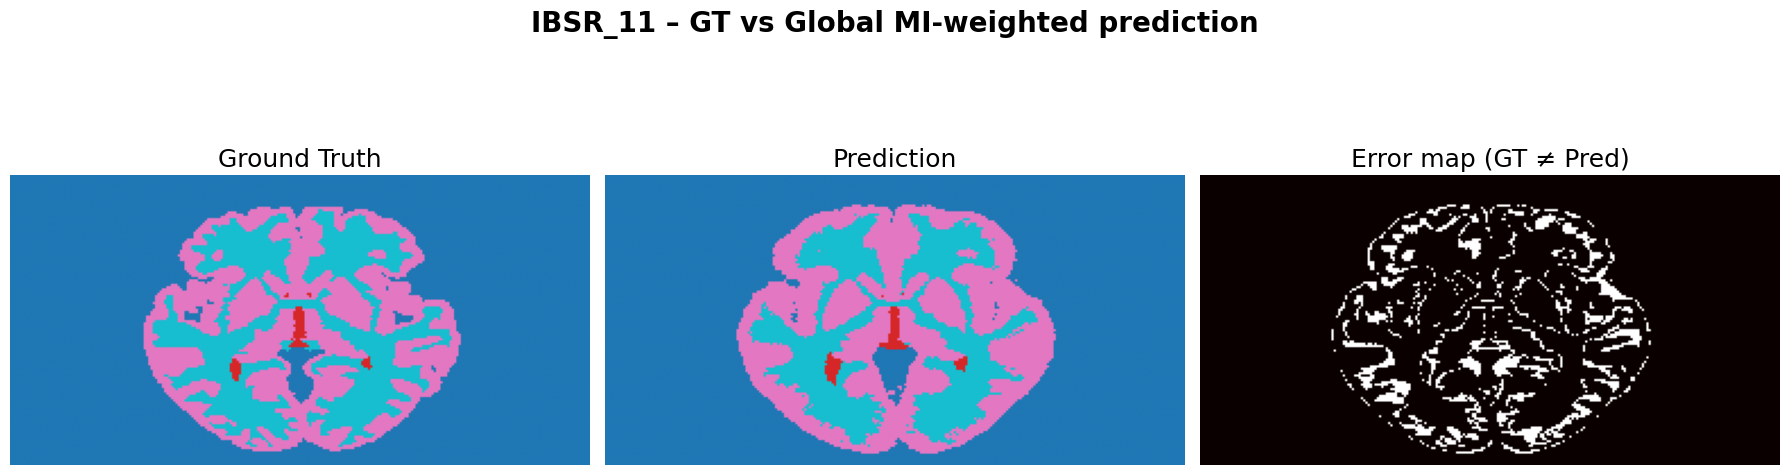

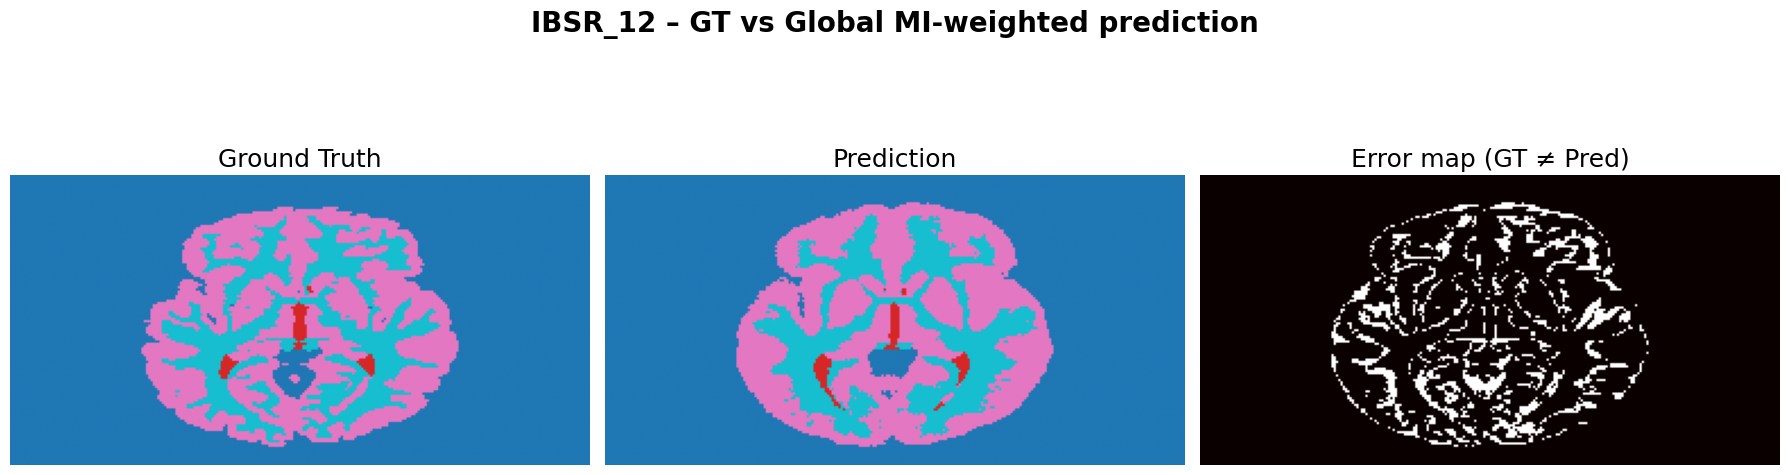

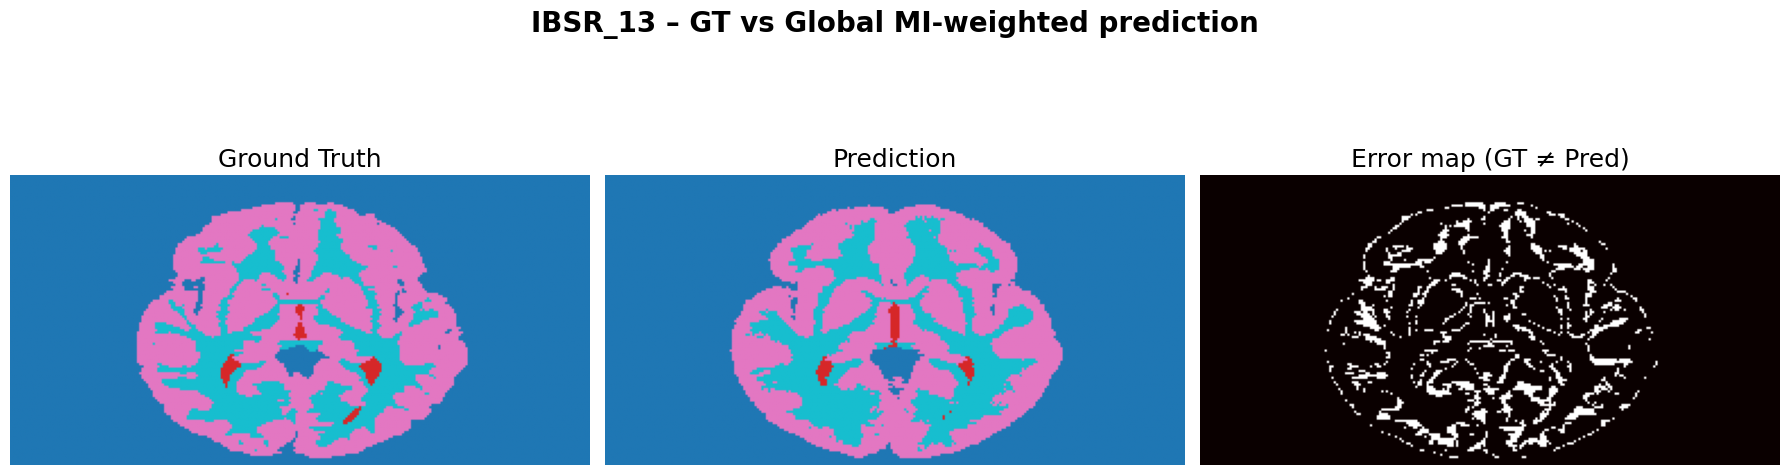

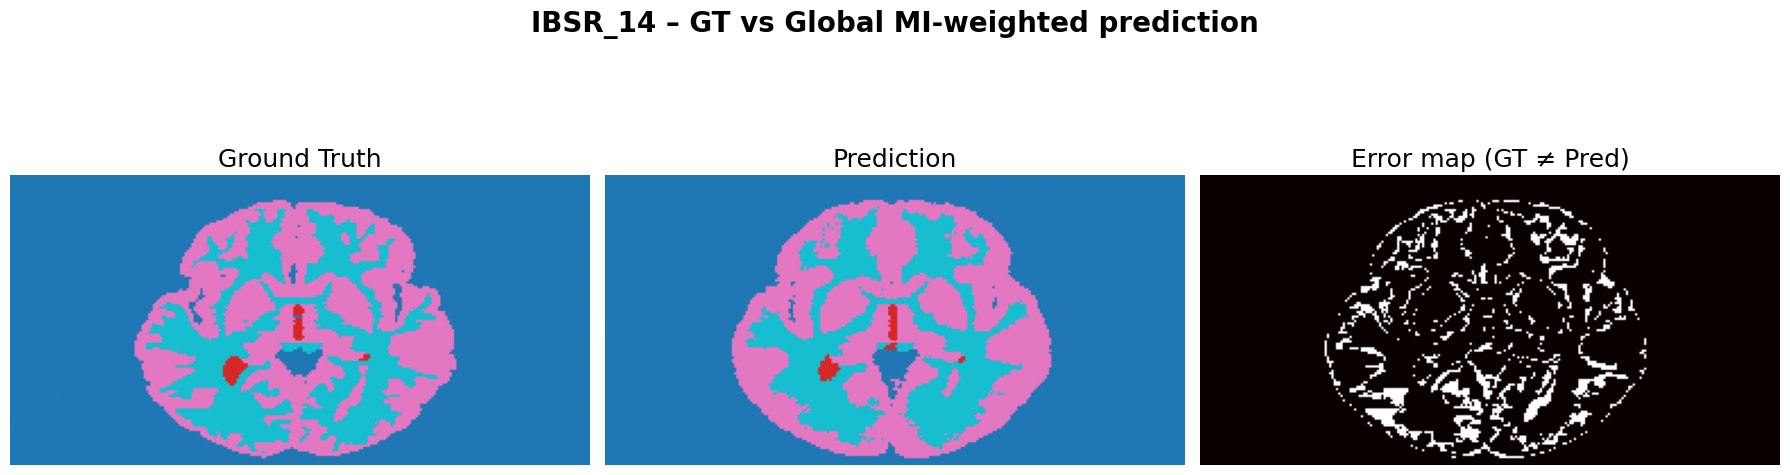

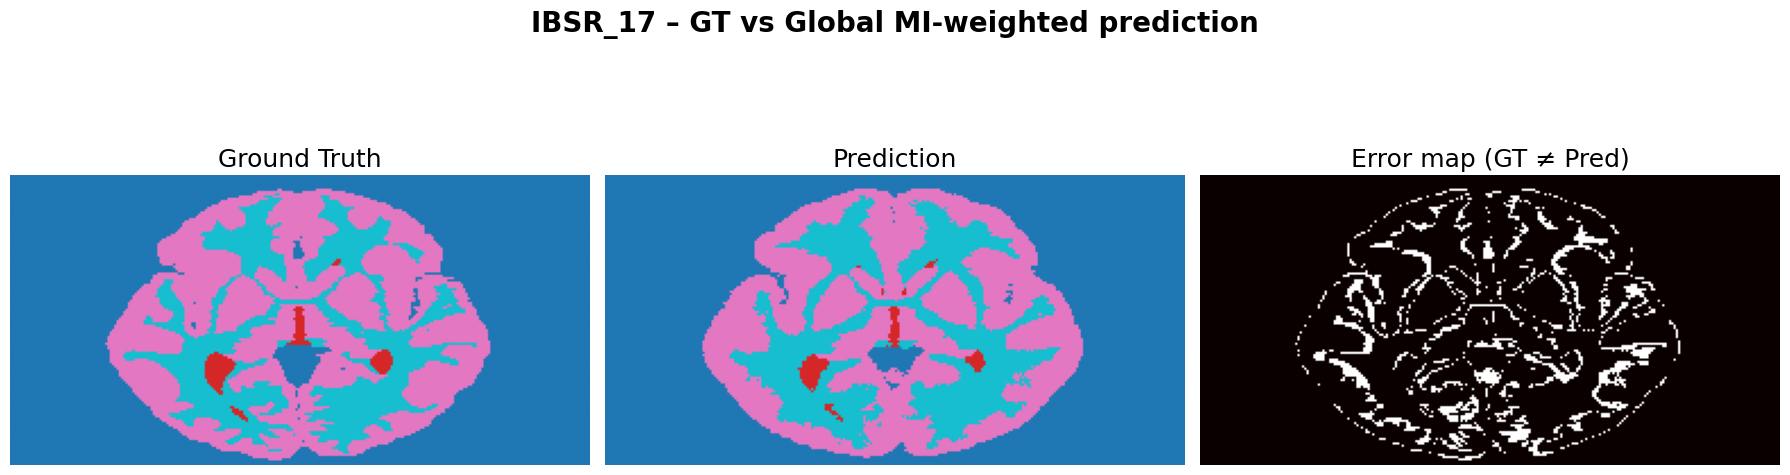

In [35]:
from pathlib import Path
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# Funciones auxiliares
# --------------------------------------------------

def load_nifti(path):
    data = nib.load(path).get_fdata()
    data = np.squeeze(data)      # <-- ELIMINA dimensiones de tamaño 1
    return data.astype(int)



def show_gt_pred_error(gt, pred, slice_idx=None, title="GT vs Prediction"):
    if slice_idx is None:
        slice_idx = gt.shape[2] // 2

    error = (gt != pred).astype(int)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle(title, fontsize=20, fontweight="bold")

    axes[0].imshow(gt[:, :, slice_idx].T, cmap="tab10", origin="lower", aspect="equal")
    axes[0].set_title("Ground Truth", fontsize=18)
    axes[0].axis("off")

    axes[1].imshow(pred[:, :, slice_idx].T, cmap="tab10", origin="lower", aspect="equal")
    axes[1].set_title("Prediction",fontsize=18)
    axes[1].axis("off")

    axes[2].imshow(error[:, :, slice_idx].T, cmap="hot", origin="lower", aspect="equal")
    axes[2].set_title("Error map (GT ≠ Pred)", fontsize=18)
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# Rutas
# --------------------------------------------------

GT_ROOT = Path(
    r"C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\TrainingValidationTestSets\Validation_Set"
)

PRED_DIR = Path(
    r"C:\Users\malki\OneDrive\Documentos\UNI\MIC\MISA\PROYECTO MISA\RESULTADOS ATLAS"
)


# --------------------------------------------------
# IDs del conjunto de validación
# --------------------------------------------------

validation_ids = [
    "IBSR_11",
    "IBSR_12",
    "IBSR_13",
    "IBSR_14",
    "IBSR_17"
]


# --------------------------------------------------
# Loop GT vs Pred vs Error
# --------------------------------------------------

for case_id in validation_ids:
    gt_path = GT_ROOT / case_id / f"{case_id}_seg.nii.gz"
    pred_path = PRED_DIR / f"{case_id}_PRED_GLOBAL_MI.nii.gz"

    if not gt_path.exists() or not pred_path.exists():
        print(f"Missing GT or prediction for {case_id}")
        continue

    gt = load_nifti(gt_path)
    pred = load_nifti(pred_path)

    show_gt_pred_error(
        gt,
        pred,
        title=f"{case_id} – GT vs Global MI-weighted prediction"
    )
